# Обробка CUBIT-InSeg і навчання YOLOv9-c

Ноутбук для Kaggle. Спочатку дивлюсь, що лежить у датасеті, далі роблю препроцесинг за схемою з п. 4.1.2 (letterbox до 1280×1280 + полігони), потім навчаю **YOLOv9-c** на сегментацію тріщин і spalling.

У Accelerator треба поставити **GPU** (T4 або P100).

> Якщо треба лише перевірити, що пайплайн взагалі стартує — в комірці з навчанням постав `EPOCHS = 3`.


In [1]:
# встановлюю ultralytics (YOLOv9-c-seg є в цій бібліотеці)
!pip -q install ultralytics

import os, random, shutil, yaml
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("ok")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 6.2 MB/s eta 0:00:00
ok


## 1. Перевірка датасету

Очікую таку структуру:

`CUBIT-InSEG/{train,val,test}/{images,labels}`

Класи в CUBIT-InSeg: `crack` і `spalling`.


In [2]:
ROOT = Path("/kaggle/input/datasets/darrriax/cubit-inseg/CUBIT-InSEG")

print("ROOT існує:", ROOT.exists())
print("Вміст:")
if ROOT.exists():
    for p in sorted(ROOT.rglob("*")):
        # не друкую кожен файл, лише папки і кількість
        pass

    for split in ["train", "val", "test"]:
        img_dir = ROOT / split / "images"
        lbl_dir = ROOT / split / "labels"
        n_img = len(list(img_dir.glob("*"))) if img_dir.exists() else 0
        n_lbl = len(list(lbl_dir.glob("*.txt"))) if lbl_dir.exists() else 0
        print(f"{split:5s}  images={n_img:5d}  labels={n_lbl:5d}  ({img_dir})")
else:
    # запасний варіант, якщо шлях трохи інший
    print("Не знайшов ROOT, дивлюсь /kaggle/input:")
    for p in Path("/kaggle/input").rglob("*"):
        if p.is_dir():
            print(" ", p)


# які class id реально є в labels
ids = set()
lbl_dir = ROOT / "train" / "labels"
if lbl_dir.exists():
    for f in list(lbl_dir.glob("*.txt"))[:400]:
        for line in f.read_text().splitlines():
            if line.strip():
                ids.add(line.split()[0])
print("class id у train (перші 400 txt):", sorted(ids, key=lambda x: int(x) if x.isdigit() else x))


ROOT існує: True
Вміст:
train  images= 5596  labels= 5596  (/kaggle/input/datasets/darrriax/cubit-inseg/CUBIT-InSEG/train/images)
val    images=  699  labels=  699  (/kaggle/input/datasets/darrriax/cubit-inseg/CUBIT-InSEG/val/images)
test   images=  701  labels=  701  (/kaggle/input/datasets/darrriax/cubit-inseg/CUBIT-InSEG/test/images)
class id у train (перші 400 txt): ['0', '1']


файл: CR1_1.JPG розмір: (4500, 3000, 3)
об'єктів у кадрі: 3
перший рядок (обрізаний):
0 0.764333 0.834444 0.764333 0.834667 0.764333 0.834889 0.764333 0.835111 0.764333 0.835333 0.764333 0.835556 0.764333 0.835778 0.764333 0.836000 0.764333 0.836222 0.764333 0.83644


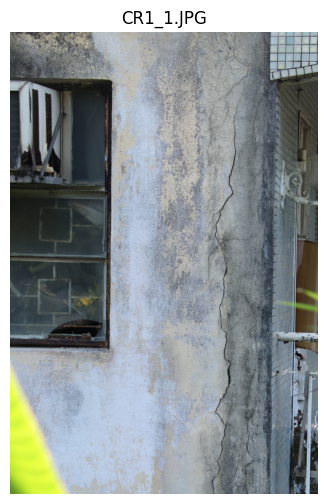

In [3]:
# дивлюсь один приклад: зображення + перші рядки анотації
split = "train"
img_dir = ROOT / split / "images"
lbl_dir = ROOT / split / "labels"

img_path = sorted(img_dir.glob("*"))[0]
stem = img_path.stem
lbl_path = lbl_dir / f"{stem}.txt"

img = cv2.imread(str(img_path))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print("файл:", img_path.name, "розмір:", img.shape)

if lbl_path.exists():
    lines = lbl_path.read_text().strip().splitlines()
    print("об'єктів у кадрі:", len(lines))
    print("перший рядок (обрізаний):")
    print(lines[0][:180] if lines else "(порожньо)")
else:
    print("немає txt для цього зображення")

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(img_path.name)
plt.show()

## 2. Препроцесинг (рис. 4.6)

Кроки:

1. анотація вже в YOLO Segmentation (`cls x1 y1 x2 y2 ...`)
2. масштабую зображення зі збереженням пропорцій (довша сторона → 1280)
3. доповнюю полями до **1280×1280**
4. так само перераховую вершини полігону (формула 4.4)
5. пікселі модель нормалізує сама як $p/255$ (формула 4.5)
6. аугментації (віддзеркалення, яскравість/контраст, слабкий шум) — **лише під час train**, щоб не плодити копії на диск


In [4]:
IMG_SIZE = 1280
CLASS_NAMES = ["crack", "spalling"]  # 0, 1 як у CUBIT-InSeg
WORK = Path("/kaggle/working/cubit_1280")

def letterbox(img, new_size=IMG_SIZE, color=(114, 114, 114)):
    """Пропорційне масштабування + padding до квадрата."""
    h, w = img.shape[:2]
    s = new_size / max(h, w)
    new_w, new_h = int(round(w * s)), int(round(h * s))
    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((new_size, new_size, 3), color, dtype=np.uint8)
    pad_x = (new_size - new_w) // 2
    pad_y = (new_size - new_h) // 2
    canvas[pad_y:pad_y + new_h, pad_x:pad_x + new_w] = resized
    return canvas, s, pad_x, pad_y, w, h


def convert_polygons(txt, s, pad_x, pad_y, w, h, new_size=IMG_SIZE):
    """Перетворення полігонів під letterbox, на виході знову YOLO-norm 0..1."""
    out = []
    if not Path(txt).exists():
        return out
    for line in Path(txt).read_text().strip().splitlines():
        parts = line.split()
        if len(parts) < 7:  # cls + хоча б 3 точки
            continue
        cls = parts[0]
        coords = list(map(float, parts[1:]))
        # якщо раптом абсолютні пікселі, а не 0..1
        if max(coords) > 1.5:
            xs = coords[0::2]
            ys = coords[1::2]
        else:
            xs = [x * w for x in coords[0::2]]
            ys = [y * h for y in coords[1::2]]
        xs = [(x * s + pad_x) / new_size for x in xs]
        ys = [(y * s + pad_y) / new_size for y in ys]
        xs = [min(1.0, max(0.0, x)) for x in xs]
        ys = [min(1.0, max(0.0, y)) for y in ys]
        poly = []
        for x, y in zip(xs, ys):
            poly.extend([f"{x:.6f}", f"{y:.6f}"])
        out.append(cls + " " + " ".join(poly))
    return out


def process_split(split):
    src_img = ROOT / split / "images"
    src_lbl = ROOT / split / "labels"
    dst_img = WORK / split / "images"
    dst_lbl = WORK / split / "labels"
    dst_img.mkdir(parents=True, exist_ok=True)
    dst_lbl.mkdir(parents=True, exist_ok=True)

    files = sorted([p for p in src_img.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}])
    n_ok = 0
    for i, img_path in enumerate(files):
        bgr = cv2.imread(str(img_path))
        if bgr is None:
            continue
        canvas, s, px, py, w, h = letterbox(bgr)
        lines = convert_polygons(src_lbl / f"{img_path.stem}.txt", s, px, py, w, h)
        cv2.imwrite(str(dst_img / f"{img_path.stem}.jpg"), canvas)
        (dst_lbl / f"{img_path.stem}.txt").write_text("\n".join(lines) + ("\n" if lines else ""))
        n_ok += 1
        if (i + 1) % 500 == 0:
            print(f"  {split}: {i+1}/{len(files)}")
    print(f"{split}: збережено {n_ok} зображень")


for split in ["train", "val", "test"]:
    process_split(split)

print("готово, робоча папка:", WORK)

  train: 500/5596
  train: 1000/5596
  train: 1500/5596
  train: 2000/5596
  train: 2500/5596
  train: 3000/5596
  train: 3500/5596
  train: 4000/5596
  train: 4500/5596
  train: 5000/5596
  train: 5500/5596
train: збережено 5596 зображень
  val: 500/699
val: збережено 699 зображень
  test: 500/701
test: збережено 701 зображень
готово, робоча папка: /kaggle/working/cubit_1280


path: /kaggle/working/cubit_1280
train: train/images
val: val/images
test: test/images
names:
  0: crack
  1: spalling
nc: 2



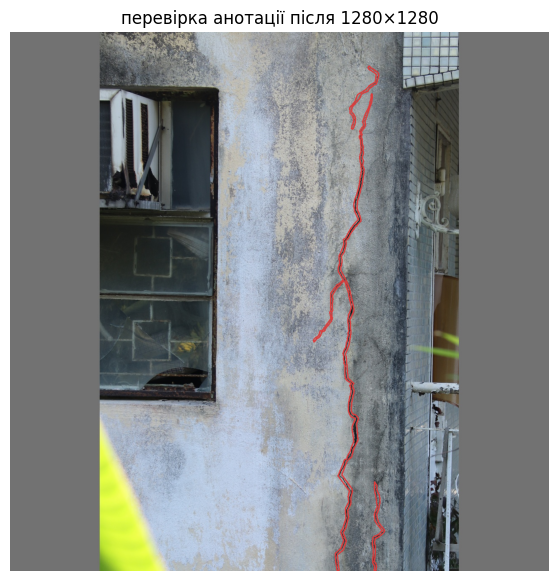

In [5]:
# yaml для ultralytics
data_yaml = {
    "path": str(WORK),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": {i: n for i, n in enumerate(CLASS_NAMES)},
    "nc": len(CLASS_NAMES),
}
yaml_path = WORK / "cubit.yaml"
yaml_path.write_text(yaml.dump(data_yaml, allow_unicode=True, sort_keys=False))
print(yaml_path.read_text())

# перевірка, що полігон після letterbox ще накладається
sample = sorted((WORK / "train" / "images").glob("*.jpg"))[0]
vis = cv2.cvtColor(cv2.imread(str(sample)), cv2.COLOR_BGR2RGB)
h, w = vis.shape[:2]
txt = (WORK / "train" / "labels" / f"{sample.stem}.txt").read_text().strip().splitlines()
for line in txt[:8]:
    p = list(map(float, line.split()))
    cls, xy = int(p[0]), p[1:]
    pts = np.array(list(zip(xy[0::2], xy[1::2])))
    pts[:, 0] *= w
    pts[:, 1] *= h
    pts = pts.astype(np.int32)
    color = (220, 60, 60) if cls == 0 else (60, 140, 220)
    cv2.polylines(vis, [pts], True, color, 2)

plt.figure(figsize=(7, 7))
plt.imshow(vis)
plt.axis("off")
plt.title("перевірка анотації після 1280×1280")
plt.show()

## 3. Навчання YOLOv9-c

Беру `yolov9c-seg.pt` (сегментація, compact). `imgsz=1280`, бо тонкі тріщини на 640 майже зникають.

Аугментації як у схемі: flip left-right і up-down, HSV (яскравість/контраст). Mosaic / mixup / великі повороти вимикаю — вони рвуть тонкі тріщини. Невеликий шум даю через `noise_gain` (якщо версія ultralytics підтримує) і через HSV.

На T4 16 ГБ при 1280 став `batch=2`. Якщо OOM — зменшити до 1.


In [6]:
from ultralytics import YOLO

EPOCHS = 35
BATCH = 2
IMGSZ = 1280
SEED = 42

model = YOLO("yolov9c-seg.pt")  # підвантажить ваги сам

train_args = dict(
    data=str(yaml_path),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=0,
    workers=2,
    project="/kaggle/working/runs",
    name="yolov9c_cubit",
    exist_ok=True,
    seed=SEED,
    pretrained=True,
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    weight_decay=0.0005,
    patience=15,
    amp=True,
    cache=False,
    # --- аугментації (гілка «Так» на схемі) ---
    fliplr=0.5,
    flipud=0.5,
    hsv_h=0.01,
    hsv_s=0.40,
    hsv_v=0.30,          # яскравість / контраст
    degrees=0.0,
    translate=0.05,
    scale=0.10,
    shear=0.0,
    perspective=0.0,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    erasing=0.0,
)

results = model.train(**train_args)
print("навчання закінчено")
print("best:", results.save_dir)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.155 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/cubit_1280/cubit.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=35, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fractio

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/35      7.27G      1.749      1.602      2.023      1.751          0          4       1280: 100% ━━━━━━━━━━━━ 2798/2798 2.6it/s 18:16
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 175/175 2.8it/s 1:02
                   all        699       6135      0.356      0.373      0.303      0.169      0.341      0.326      0.274      0.132

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/35      7.27G      1.575      1.443      1.767      1.606          0         38       1280: 100% ━━━━━━━━━━━━ 2798/2798 2.6it/s 18:15
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 175/175 2.8it/s 1:02
                   all        699       6135      0.493      0.527      0.491      0.336      0.474      0.495      0.466      0.281



## 4. Графіки і таблиця метрик

Ultralytics сам пише `results.csv` і `results.png` у папку прогону. Звідти будую таблицю (Box / Mask mAP) і копіюю ваги в `/kaggle/working`, щоб їх було зручно Download.


run_dir: /kaggle/working/runs/yolov9c_cubit
файли: ['confusion_matrix.png', 'train_batch0.jpg', 'val_batch2_labels.jpg', 'train_batch69952.jpg', 'train_batch69951.jpg', 'results.png', 'train_batch1.jpg', 'weights', 'MaskR_curve.png', 'BoxR_curve.png', 'MaskPR_curve.png', 'val_batch1_pred.jpg', 'val_batch0_pred.jpg', 'labels.jpg', 'val_batch1_labels.jpg', 'results.csv', 'args.yaml', 'BoxP_curve.png', 'BoxF1_curve.png', 'MaskP_curve.png', 'val_batch2_pred.jpg', 'train_batch2.jpg', 'train_batch69950.jpg', 'val_batch0_labels.jpg', 'confusion_matrix_normalized.png', 'BoxPR_curve.png', 'MaskF1_curve.png']


,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,train/sem_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),...,metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,val/sem_loss,lr/pg0,lr/pg1,lr/pg2
30,31,35692.7,0.49933,0.64224,0.37565,0.85204,0,0.75490,0.78260,0.70641,...,0.67097,0.49797,0.55333,0.64775,2.13430,0.92751,0,0.000151,0.000151,0.000151
31,32,36839.3,0.49658,0.63894,0.37356,0.85113,0,0.78957,0.77203,0.72941,...,0.69094,0.50582,0.54387,0.64499,1.77149,0.91024,0,0.000123,0.000123,0.000123
32,33,37986.8,0.47601,0.62040,0.35545,0.84485,0,0.79122,0.78786,0.73721,...,0.69964,0.51162,0.53093,0.63469,1.68866,0.90985,0,0.000095,0.000095,0.000095
33,34,39133.2,0.46776,0.61836,0.34994,0.83951,0,0.79375,0.78398,0.73649,...,0.70104,0.51174,0.52034,0.62270,1.64791,0.90326,0,0.000067,0.000067,0.000067
34,35,40284.2,0.45169,0.60080,0.33593,0.83434,0,0.81766,0.78529,0.75000,...,0.71478,0.51868,0.50453,0.61877,1.64373,0.89247,0,0.000038,0.000038,0.000038


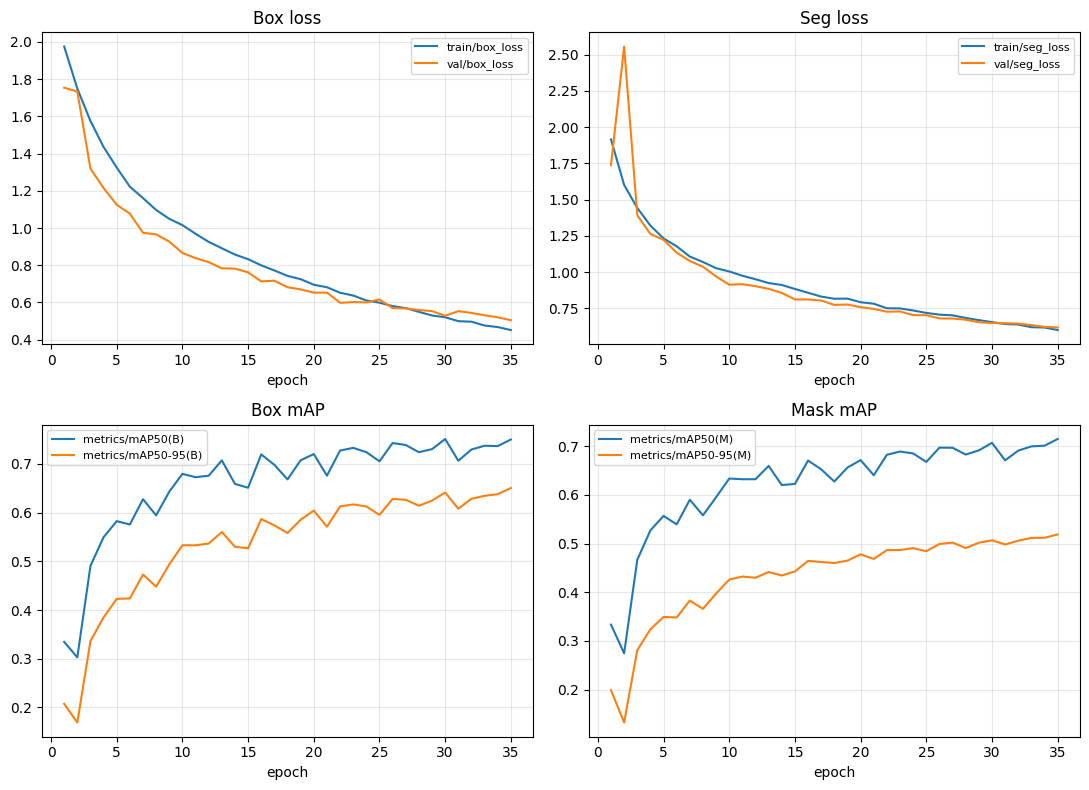

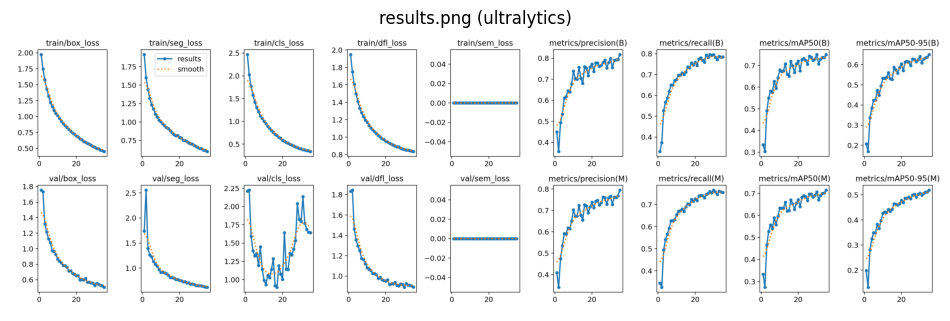

In [7]:
run_dir = Path("/kaggle/working/runs/yolov9c_cubit")
csv_path = run_dir / "results.csv"
print("run_dir:", run_dir)
print("файли:", [p.name for p in run_dir.iterdir()][:30])

df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]
display(df.tail(5))

# графіки навчання
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

def col_like(part):
    for c in df.columns:
        if part in c:
            return c
    return None

plots = [
    (axes[0, 0], col_like("train/box_loss"), col_like("val/box_loss"), "Box loss"),
    (axes[0, 1], col_like("train/seg_loss"), col_like("val/seg_loss"), "Seg loss"),
    (axes[1, 0], col_like("metrics/mAP50(B)"), col_like("metrics/mAP50-95(B)"), "Box mAP"),
    (axes[1, 1], col_like("metrics/mAP50(M)"), col_like("metrics/mAP50-95(M)"), "Mask mAP"),
]
x = df[col_like("epoch")] if col_like("epoch") else range(1, len(df) + 1)
for ax, c1, c2, title in plots:
    if c1:
        ax.plot(x, df[c1], label=c1)
    if c2:
        ax.plot(x, df[c2], label=c2)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("/kaggle/working/training_curves.png", dpi=140)
plt.show()

# готова картинка від ultralytics, якщо є
res_png = run_dir / "results.png"
if res_png.exists():
    im = plt.imread(str(res_png))
    plt.figure(figsize=(12, 8))
    plt.imshow(im)
    plt.axis("off")
    plt.title("results.png (ultralytics)")
    plt.show()

In [8]:
# таблиця фінальних метрик (остання епоха + best по mask mAP50)
last = df.iloc[-1]

def get(name_part, row=None):
    row = last if row is None else row
    c = col_like(name_part)
    return float(row[c]) if c is not None else None

mask50_col = col_like("metrics/mAP50(M)")
best_idx = int(df[mask50_col].idxmax()) if mask50_col else len(df) - 1
best = df.iloc[best_idx]

table = pd.DataFrame({
    "метрика": [
        "Box Precision",
        "Box Recall",
        "Box mAP@0.5",
        "Box mAP@0.5:0.95",
        "Mask Precision",
        "Mask Recall",
        "Mask mAP@0.5",
        "Mask mAP@0.5:0.95",
    ],
    "остання епоха": [
        get("metrics/precision(B)"),
        get("metrics/recall(B)"),
        get("metrics/mAP50(B)"),
        get("metrics/mAP50-95(B)"),
        get("metrics/precision(M)"),
        get("metrics/recall(M)"),
        get("metrics/mAP50(M)"),
        get("metrics/mAP50-95(M)"),
    ],
    "best (за Mask mAP@0.5)": [
        get("metrics/precision(B)", best),
        get("metrics/recall(B)", best),
        get("metrics/mAP50(B)", best),
        get("metrics/mAP50-95(B)", best),
        get("metrics/precision(M)", best),
        get("metrics/recall(M)", best),
        get("metrics/mAP50(M)", best),
        get("metrics/mAP50-95(M)", best),
    ],
})
display(table.round(4))
table.to_csv("/kaggle/working/metrics_table.csv", index=False)
print("епоха best:", int(best[col_like("epoch")]) if col_like("epoch") else best_idx + 1)

,метрика,остання епоха,best (за Mask mAP@0.5)
0,Box Precision,0.8177,0.8177
1,Box Recall,0.7853,0.7853
2,Box mAP@0.5,0.7500,0.7500
3,Box mAP@0.5:0.95,0.6505,0.6505
4,Mask Precision,0.7946,0.7946
5,Mask Recall,0.7554,0.7554
6,Mask mAP@0.5,0.7148,0.7148
7,Mask mAP@0.5:0.95,0.5187,0.5187


епоха best: 35


best.pt: /kaggle/working/runs/yolov9c_cubit/weights/best.pt існує: True

=== VAL ===
Ultralytics 8.4.155 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv9c-seg summary (fused): 169 layers, 27,626,070 parameters, 0 gradients, 147.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2133.4±412.1 MB/s, size: 192.0 KB)
val: Scanning /kaggle/working/cubit_1280/val/labels.cache... 699 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 699/699 195.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 350/350 2.4it/s 2:23
                   all        699       6135      0.825      0.787      0.759      0.659      0.794      0.753      0.712      0.515
                 crack        299       5029      0.698      0.599      0.552      0.394      0.641      0.541      0.471      0.171
              spalling        400       1106      0.951      0.974      0.96

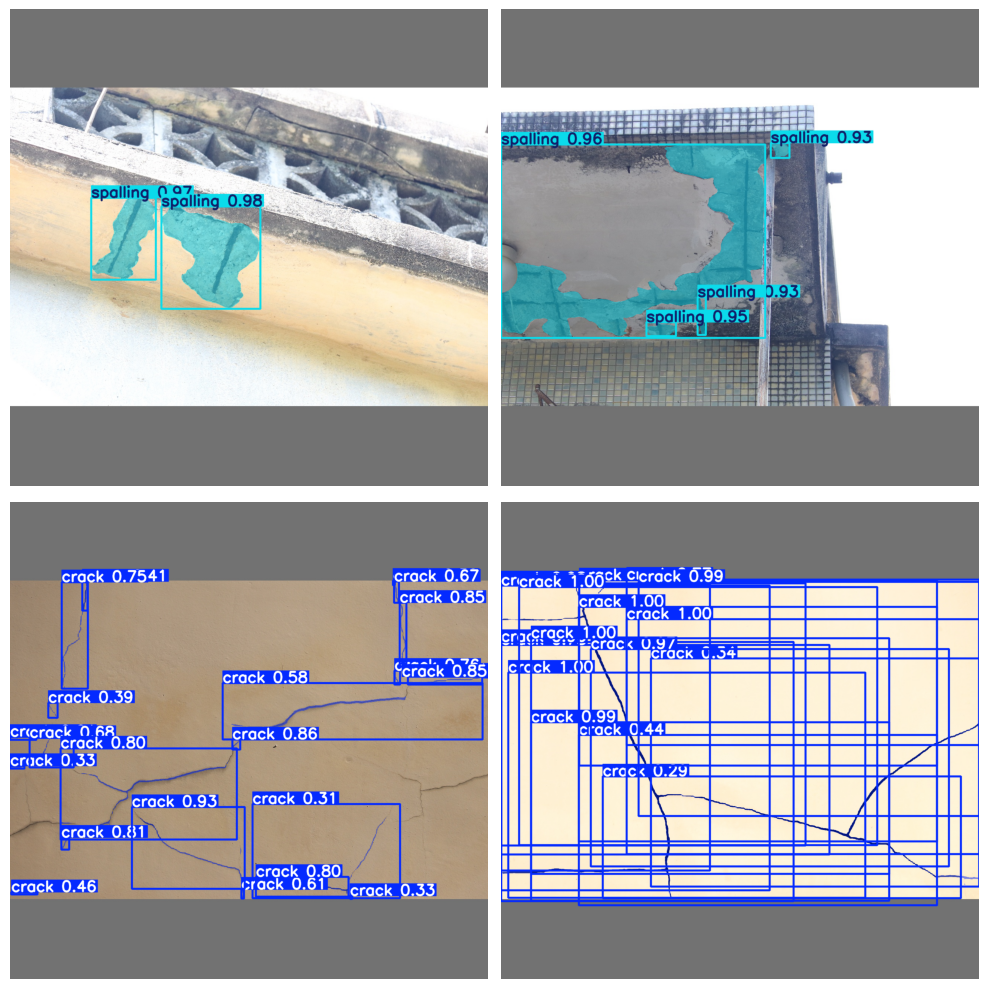

In [9]:
# оцінка на val і test + кілька візуалізацій
best_pt = run_dir / "weights" / "best.pt"
print("best.pt:", best_pt, "існує:" , best_pt.exists())

trained = YOLO(str(best_pt))

print("\n=== VAL ===")
val_res = trained.val(data=str(yaml_path), split="val", imgsz=IMGSZ, batch=BATCH, device=0)
print("\n=== TEST ===")
test_res = trained.val(data=str(yaml_path), split="test", imgsz=IMGSZ, batch=BATCH, device=0)

# 4 випадкові тестові кадри
test_imgs = sorted((WORK / "test" / "images").glob("*.jpg"))
random.seed(0)
sample = random.sample(test_imgs, k=min(4, len(test_imgs)))
pred = trained.predict(source=[str(p) for p in sample], imgsz=IMGSZ, conf=0.25, save=False, verbose=False)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, r in zip(axes.ravel(), pred):
    ax.imshow(r.plot()[:, :, ::-1])  # BGR -> RGB
    ax.axis("off")
plt.tight_layout()
plt.savefig("/kaggle/working/test_examples.png", dpi=140)
plt.show()

In [10]:
# зберігаю модель у корінь Output, щоб скачати з Kaggle
out_best = Path("/kaggle/working/yolov9c_cubit_best.pt")
out_last = Path("/kaggle/working/yolov9c_cubit_last.pt")
shutil.copy(run_dir / "weights" / "best.pt", out_best)
shutil.copy(run_dir / "weights" / "last.pt", out_last)

print("збережено:")
print(" ", out_best, out_best.stat().st_size / 1e6, "МБ")
print(" ", out_last, out_last.stat().st_size / 1e6, "МБ")
print(" ", "/kaggle/working/metrics_table.csv")
print(" ", "/kaggle/working/training_curves.png")

збережено:
  /kaggle/working/yolov9c_cubit_best.pt 56.387993 МБ
  /kaggle/working/yolov9c_cubit_last.pt 56.387993 МБ
  /kaggle/working/metrics_table.csv
  /kaggle/working/training_curves.png
